In [275]:
# Install NLTK
!pip install nltk

In [276]:
# Import packages
import nltk, os
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem import PorterStemmer, LancasterStemmer

In [277]:
# Install punkt tokenizer models
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\camer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [278]:
# Path of the texts
path = './data/Part_I_1-2'
# The list of items
files = os.listdir(path)
# Loop to add each file in the Part_I_1-2 folder to the texts list
texts = []
for text in files:
    texts.append(text)

In [279]:
def text_tokens(file):
    """
    Performs sentence splitting and word tokenization.

    Parameter:
        file: TXT file of which the sentences will be split and the words tokenizede.
    Returns:
        List: split sentences containing tokenized words
    """
    # Open the file
    with open(f"./data/Part_I_1-2/{file}", "r") as f:
        # Tokenize the split sentences into words
        return [nltk.word_tokenize(sent) for sent in nltk.sent_tokenize(f.read())]

In [280]:
def text_tokens_amt(words, file):
    """
    Counts the word frequency of word tokens of split sentences in a TXT file.

    Parameter:
        file: TXT file of which the word frequency will be counted.
    Returns:
        Counter: dictionary contains word token, frequency pairs
    """
    # Open the file
    with open(f"./data/Part_I_1-2/{file}", "r") as f:
        # Tokenize the split sentences into words
        return Counter(word for sublist in words for word in sublist)

In [281]:
# Instantiate the text_token_count dictionary
text_token_count = {}

# Loop over the files in the texts list
for file in texts:
    # Add a key, value pair consisting of the file name and a frequency count of the words
    words = text_tokens(file)
    text_token_count.update({file: text_tokens_amt(words, file)})

In [282]:
# Instantiate the total_token_count Counter()
total_token_count = Counter()
# Loop over the keys in the text_token_count
for key in text_token_count:
    # Add the word frequency count to the total_token_count
    total_token_count += text_token_count[key]

In [283]:
# Add the total_token_count to the text_token_count
text_token_count = dict(text_token_count, total_token_count=total_token_count)

In [284]:
def histogram(key, specific_dict):
    """
    Creates a bar plot of the 25 most common words.

    Parameter:
        key: Key of the text_token_count dictionary.
    Returns:
        Bar plot.
    """
    # Turns the 25 most common words (values) of a specific key into a dictionary
    word_freq = dict(specific_dict[key].most_common(25))
    # Turns the words into a list
    words = list(word_freq.keys())
    # Turns the frequency into a list
    freq = list(word_freq.values())

    # Change the key to 'total'
    if (key == 'total_token_count') or (key == 'total_porter_count') or (key == 'total_lancaster_count'):
        key = 'Total'

    # Plot a bar plot
    fig, ax = plt.subplots(figsize=(6, 2))
    bar_container = ax.bar(words, freq)
    ax.set(ylabel='Frequency', xlabel='Words', title=f'Top 25 Most Common Words in {key}')
    plt.xticks(rotation=60)
    ax.bar_label(bar_container, fmt='{:,.0f}', rotation=45)

    return plt.show()

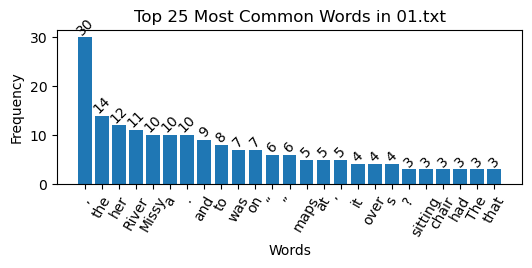

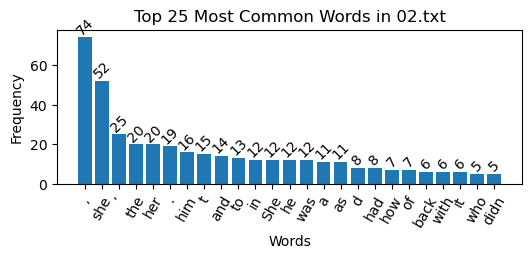

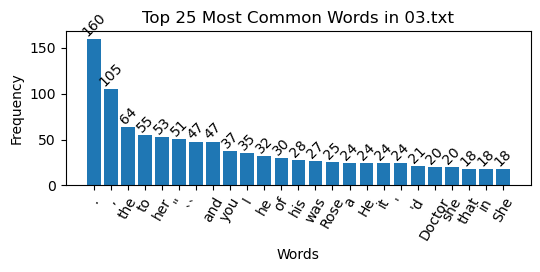

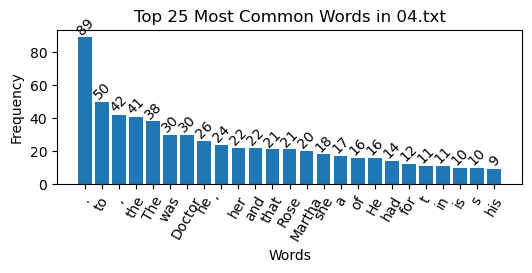

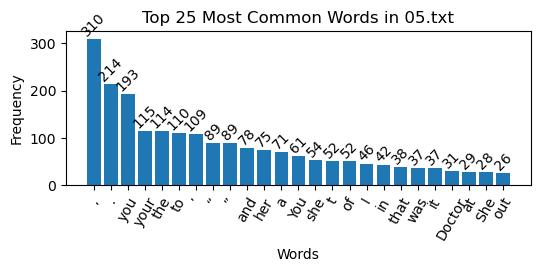

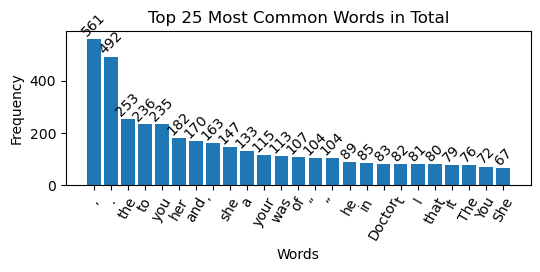

In [285]:
# Loop over the keys in the text_token_count dictionary
for key in text_token_count:
    # Run the bar_plot(key, specific_dict) function
    histogram(key, text_token_count)

In [286]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

In [287]:
# Instantiate the tokens dictionary
tokens = {}

# Loop over the files in the texts list
for file in texts:
    # Add a key, value pair consisting of the file name and split sentences of tokenized words words
    tokens.update({file: text_tokens(file)})
    # Turn the list of lists into a single list
    tokens[file] = [word for sublist in tokens[file] for word in sublist]

In [288]:
# Instantiate dictionaries
porter_words = {}
lancaster_words = {}

# Loop over the keys in the tokens dictionary
for key in tokens:
    # Add a key, value pair consisting of the key name and Porter stemmed words
    porter_words.update({key: [porter.stem(word) for word in tokens[key]]})
    # Add a key, value pair consisting of the key name and Lancaster stemmed words
    lancaster_words.update({key: [lancaster.stem(word) for word in tokens[key]]})

In [289]:
# Instantiate dictionaries
porter_token_count = {}
lancaster_token_count = {}

# Loop over the files in the texts list
for file in texts:
    # Add a key, value pair consisting of the file name and a frequency count of the words
    porter_token_count.update({file: Counter(porter_words[file])})
    lancaster_token_count.update({file: Counter(lancaster_words[file])})

In [290]:
# Instantiate the Counters
total_porter_count = Counter()
total_lancaster_count = Counter()

# Loop over the keys in the porter_token_count
for key in porter_token_count:
    # Add the word frequency count to the total_porter_count
    total_porter_count += porter_token_count[key]

# Loop over the keys in the lancaster_token_count
for key in lancaster_token_count:
    # Add the word frequency count to the total_lancaster_count
    total_lancaster_count += lancaster_token_count[key]

In [291]:
# Add the total_porter_count to the porter_token_count
porter_token_count = dict(porter_token_count, total_porter_count=total_porter_count)

# Add the total_lancaster_count to the lancaster_token_count
lancaster_token_count = dict(lancaster_token_count, total_lancaster_count=total_lancaster_count)

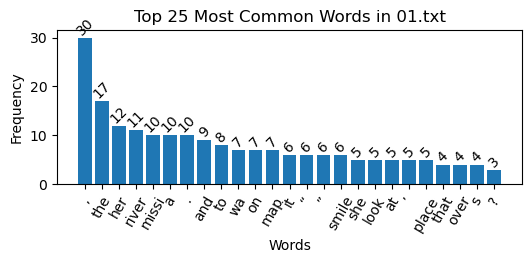

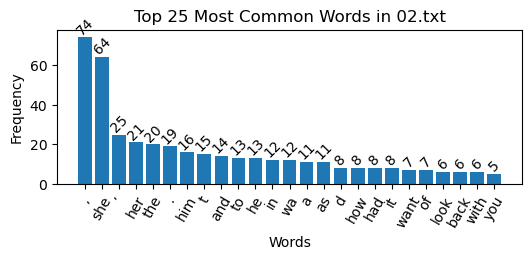

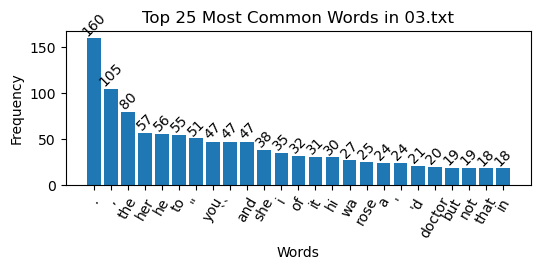

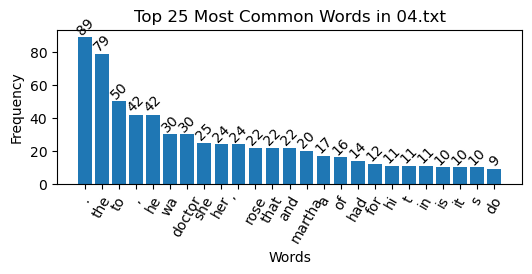

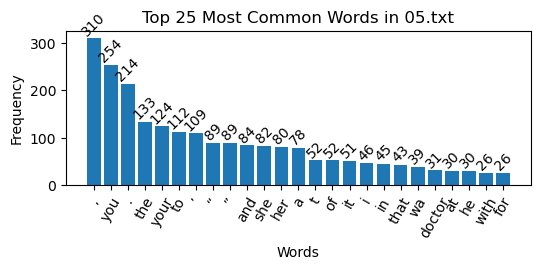

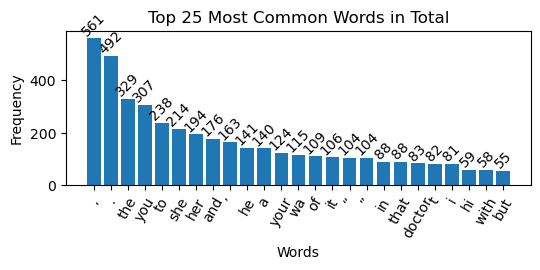

In [292]:
# Loop over the keys in the porter_token_count dictionary
for key in porter_token_count:
    # Run the bar_plot(key, specific_dict) function
    histogram(key, porter_token_count)

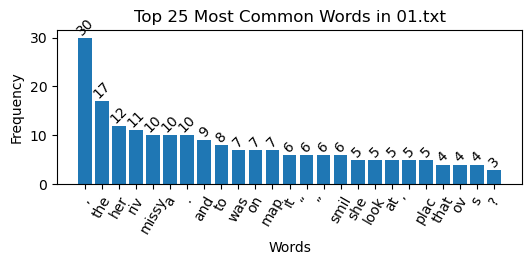

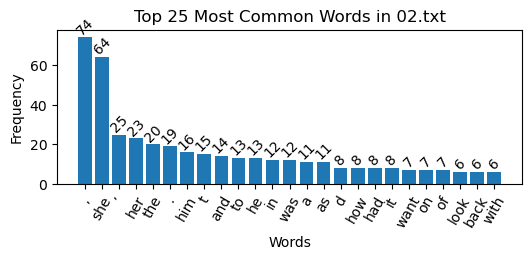

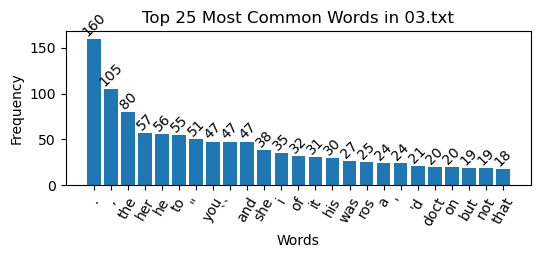

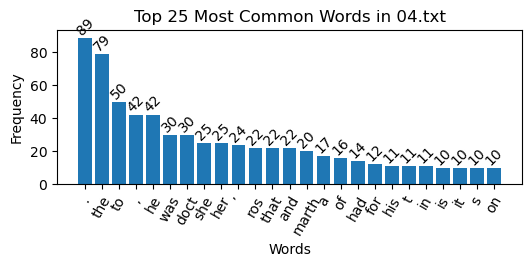

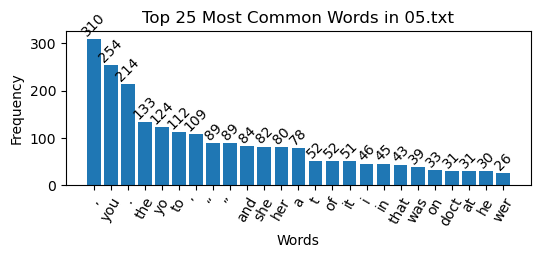

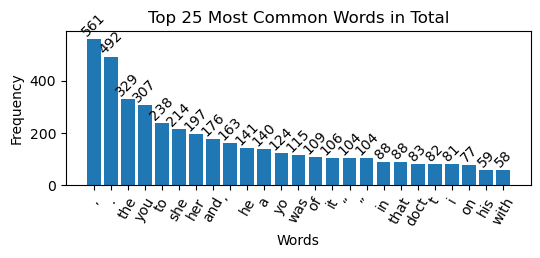

In [293]:
# Loop over the keys in the lancaster_token_count dictionary
for key in lancaster_token_count:
    # Run the bar_plot(key, specific_dict) function
    histogram(key, lancaster_token_count)